## Data Preparation

## Set up dataloaders

In [1]:
import os
import cv2
import torch
import numpy as np
from torch.utils.data import Dataset
import torchvision.transforms as transforms

class MergedImageDataset(Dataset):

    def __init__(self,
                 root_dir,
                 split='train',
                 pre_seq_length=30,
                 aft_seq_length=5,
                 suffix='.mp4',
                 frame_size=256):
        
        self.pre_seq_length = pre_seq_length
        self.aft_seq_length = aft_seq_length
        self.total_frames = pre_seq_length + aft_seq_length
        self.frame_size = frame_size

        self.mean = None
        self.std = None
        self.data_name = "limited-fov"
        
        self.folder = os.path.join(root_dir, split)
        self.video_paths = [
            os.path.join(self.folder, f)
            for f in os.listdir(self.folder)
            if f.endswith(suffix)
        ]

    def __len__(self):
        return len(self.video_paths)

    def _sample_frames(self, video_path):
        video = cv2.VideoCapture(video_path)
        total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

        frame_idxs = np.linspace(
            0, total_frames - 1,
            self.total_frames,
            dtype=int
        )

        frames = []

        for idx in frame_idxs:
            video.set(cv2.CAP_PROP_POS_FRAMES, idx)
            ret, frame = video.read()
            if not ret:
                continue

            frame = cv2.resize(frame, (self.frame_size, self.frame_size))

            frames.append(frame)

        video.release()

        frames = np.stack(frames)
        return frames


    def mask_ego_vehicle_soft(self, img, mask_radius=5, feather=2):
        h, w = img.shape[:2]
        cx, cy = w // 2, h // 2
    
        y, x = np.ogrid[:h, :w]
        dist = np.sqrt((x - cx)**2 + (y - cy)**2)
    
        mask = np.ones((h, w), dtype=np.float32)
    
        inner = dist <= mask_radius
        outer = (dist > mask_radius) & (dist < mask_radius + feather)
    
        mask[inner] = 0.0
        mask[outer] = (dist[outer] - mask_radius) / feather
    
        masked = img.astype(np.float32) * mask[:, :, None]
    
        return masked
    
    
    def gradient_magnitude(self, img):
        img = img.astype(np.float32)
    
        gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    
        mag = np.sqrt(gx**2 + gy**2)
        mag = np.sum(mag, axis=2)
    
        return mag
    
    
    def compute_sequential_translations(self, images):
        """
        images: list of BGR images (uint8)
        returns: Nx2 array of global (dx, dy)
        """
    
        h, w = images[0].shape[:2]
        window = cv2.createHanningWindow((w, h), cv2.CV_32F)
    
        global_translations = [(0.0, 0.0)]
        cumulative_dx = 0.0
        cumulative_dy = 0.0
    
        prev_img = images[0]
    
        prev_proc = self.gradient_magnitude(
            self.mask_ego_vehicle_soft(prev_img)
        ) * window
    
        for i in range(1, len(images)):
    
            curr_img = images[i]
    
            curr_proc = self.gradient_magnitude(
                self.mask_ego_vehicle_soft(curr_img)
            ) * window
    
            shift, response = cv2.phaseCorrelate(prev_proc, curr_proc)
    
            dx, dy = shift
            dx = -dx
            dy = -dy
    
            # accumulate global position
            cumulative_dx += dx
            cumulative_dy += dy
    
            global_translations.append((cumulative_dx, cumulative_dy))
    
            prev_proc = curr_proc
    
        return np.array(global_translations)
    
    
    def crop_to_second_frame(self, merged, dx, dy, offset_x, offset_y, img2_shape):
        """
        merged: final large stitched image
        dx, dy: global shift of image 2 relative to image 1
        offset_x, offset_y: canvas offsets used during warping
        img2_shape: shape of original image 2
        """
    
        h2, w2 = img2_shape[:2]
    
        x_start = int(round(dx + offset_x))
        y_start = int(round(dy + offset_y))
    
        x_end = x_start + w2
        y_end = y_start + h2
    
        cropped = merged[y_start:y_end, x_start:x_end]
    
        return cropped
    
    
    def shift_and_merge_images(self, images):

        # estimate translations
        translations = self.compute_sequential_translations(images)
        translations = np.array(translations)
    
        # Determine all image corners in global frame
        corners = []
    
        for (dx, dy), img in zip(translations, images):
            h, w = img.shape[:2]
            corners.append([
                dx, dy,
                dx + w, dy,
                dx + w, dy + h,
                dx, dy + h
            ])
    
        corners = np.array(corners).reshape(-1, 2)
    
        xmin, ymin = np.floor(corners.min(axis=0)).astype(int)
        xmax, ymax = np.ceil(corners.max(axis=0)).astype(int)
    
        canvas_width = xmax - xmin
        canvas_height = ymax - ymin
    
        # offset so everything is positive
        offset_x = -xmin
        offset_y = -ymin
    

        # warp images into canvas
        stack = []
    
        for (dx, dy), img in zip(translations, images):
    
            M = np.array([
                [1, 0, dx + offset_x],
                [0, 1, dy + offset_y]
            ], dtype=np.float32)
    
            warped = cv2.warpAffine(
                img,
                M,
                (canvas_width, canvas_height),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_CONSTANT,
                borderValue=(0, 0, 0)
            )
    
            stack.append(warped.astype(np.float32))
    
        stack = np.stack(stack, axis=0)
    
        # mask true where pixel is not black
        valid_mask = np.any(stack > 40, axis=-1)
    
        merged = np.zeros_like(stack[0])
    
        for c in range(3):
            channel = stack[:, :, :, c]
    
            # Replace invalid pixels with NaN
            channel_masked = np.where(valid_mask, channel, np.nan)
    
            # Median ignoring NaNs
            merged[:, :, c] = np.nanmedian(channel_masked, axis=0)
    
        # Replace remaining NaNs (areas never seen) with black
        merged = np.nan_to_num(merged, nan=0.0)
    
        merged = np.clip(merged, 0, 255).astype(np.uint8)
    
        dx = translations[1][0]
        dy = translations[1][1]
    
        cropped = self.crop_to_second_frame(
            merged,
            dx,
            dy,
            offset_x,
            offset_y,
            images[1].shape
        )
    
        return cropped

    
    def __getitem__(self, idx):

        video_path = self.video_paths[idx]

        frames = self._sample_frames(video_path)

        x = frames[:self.pre_seq_length]
        y = frames[self.pre_seq_length:]


        ######
        merged_frames = []
        step = 2
        for i in range(0, self.pre_seq_length-1, step):
            merged = self.shift_and_merge_images([x[i], x[i+step-1]])
            merged_frames.append(merged)
        # step = 2
        # for i in range(0, self.pre_seq_length-step, step):
        #     merged = self.shift_and_merge_images([x[i], x[i+step-1]])
        #     merged_frames.append(merged)
        
        # past_frames = []
        # for img in x:
        #     label = self.convert_to_labels(img)
        #     past_frames.append(label)

        # stack = np.stack(past_frames, axis=0)
        # processed_frames = self.build_features(stack)

        x = x.astype(np.float32) / 255.0
        y = y.astype(np.float32) / 255.0

        # sample 5 frames, save for later
        # T, H, W, C = frames.shape
        # selected_indices = np.linspace(0, self.pre_seq_length - 1, 5, dtype=int)
        input_frames = []

        # selected_frames = x[[27, 28, 29]]#x[selected_indices]

        # for frame in selected_frames:
        #     input_frames.append(frame)

        for frame in merged_frames:
            input_frames.append(frame.astype(np.float32) / 255.0)

        # print("merged: ", merged_frames.shape)

        x = np.stack(input_frames).transpose(0, 3, 1, 2) # (T, H, W, C) to (T, C, H, W)
        y = np.stack(y).transpose(0, 3, 1, 2) # (T, H, W, C) to (T, C, H, W)

        # Convert to tensor
        x = torch.from_numpy(x)
        y = torch.from_numpy(y)

        return x, y

In [2]:
from torch.utils.data import DataLoader

batch_size = 2
num_workers = 4 # increase if CPU allows

root_dir = '/mnt/active_storage/Knut/LimitedFOVData/final_data_color/'

pre_seq_length = 30
aft_seq_length = 5
frame_size = 256

train_dataset = MergedImageDataset(
    root_dir=root_dir,
    split='train',
    pre_seq_length=pre_seq_length,
    aft_seq_length=aft_seq_length,
    frame_size=frame_size
)

val_dataset = MergedImageDataset(
    root_dir=root_dir,
    split='val',
    pre_seq_length=pre_seq_length,
    aft_seq_length=aft_seq_length,
    frame_size=frame_size
)

test_dataset = MergedImageDataset(
    root_dir=root_dir,
    split='test',
    pre_seq_length=pre_seq_length,
    aft_seq_length=aft_seq_length,
    frame_size=frame_size
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,      
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

/tmp/ipykernel_1734525/160408314.py:258: RuntimeWarning: All-NaN slice encountered
  merged[:, :, c] = np.nanmedian(channel_masked, axis=0)


(15, 3, 256, 256)


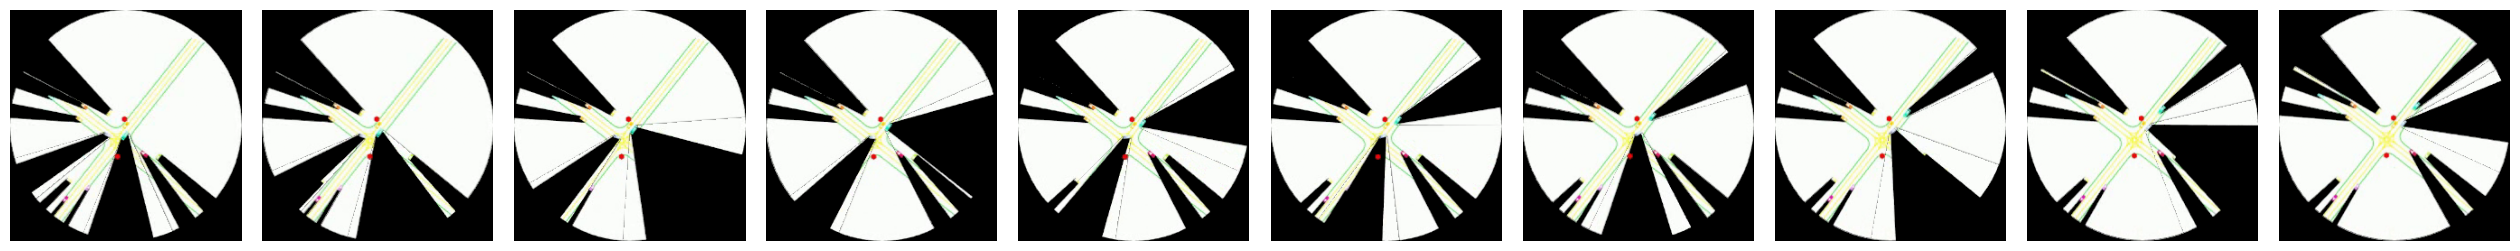

In [3]:
from openstl.utils import show_video_line

train_x, train_y = train_loader.dataset[2]

train_x = train_x.numpy()

# show the input frames as an example
example_idx = 0
print(train_x.shape)
show_video_line(train_x, ncols=10, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

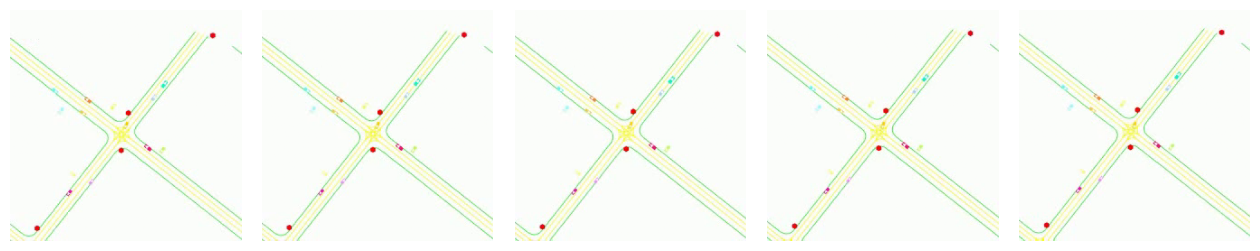

In [4]:
# show the future frames as an example
train_y = train_y.numpy()
show_video_line(train_y, ncols=5, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

## Train and evaluate

In [5]:
exp_name = 'simvp_10ep_15color_merged_only' #'tau_10ep_17color_merged' #'simvp_10ep_color'

feature_img_length = 15

custom_training_config = {
    'pre_seq_length': feature_img_length,
    'aft_seq_length': aft_seq_length,
    'total_length': feature_img_length + aft_seq_length,
    'batch_size': batch_size,
    'val_batch_size': batch_size,
    'epoch': 10,
    'lr': 0.001,   
    'metrics': ['mse', 'mae', 'ssim'],
    'ex_name': exp_name,
    'dataname': 'custom',
    'in_shape': [feature_img_length, 3, frame_size, frame_size],
    'gpus': [1]
}

custom_model_config = { # SimVPv2 model config
    'method': 'SimVP',
    'spatio_kernel_enc': 3,
    'spation_kernel_dec': 3,
    'model_type': 'gSTA',
    'N_S': 4,
    'N_T': 8,
    'hid_S': 64,
    'hid_T': 512
}

# custom_model_config = { # TAU model config
#     'method': 'TAU',
#     'spatio_kernel_enc': 3,
#     'spatio_kernel_dec': 3,
#     'model_type': 'tau',
#     'hid_S': 64,
#     'hid_T': 512,
#     'N_T': 8,
#     'N_S': 4,
#     'alpha': 0.1,
#     'drop_path': 0,
# }


In [6]:
from openstl.api import BaseExperiment
from openstl.utils import create_parser, default_parser

args = create_parser().parse_args([])
config = args.__dict__

# update the training config
config.update(custom_training_config)
# update the model config
config.update(custom_model_config)
# fulfill with default values
default_values = default_parser()
for attribute in default_values.keys():
    if config[attribute] is None:
        config[attribute] = default_values[attribute]



In [7]:

# train model
exp = BaseExperiment(args, dataloaders=(train_loader, val_loader, test_loader), strategy='auto')
print('>'*35 + ' training ' + '<'*35)
exp.train()


In [8]:

# re-define training config with test=true and fps=True to get fps, FLOPS along with other metrics
custom_training_config = {
    'pre_seq_length': feature_img_length,
    'aft_seq_length': aft_seq_length,
    'total_length': feature_img_length + aft_seq_length,
    'batch_size': batch_size,
    'val_batch_size': batch_size,
    'epoch': 10,
    'lr': 0.001,   
    'metrics': ['mse', 'mae', 'ssim'],
    'ex_name': exp_name,
    'dataname': 'custom',
    'in_shape': [feature_img_length, 3, frame_size, frame_size],
    'gpus': [1],
    'test': True,
    'fps': True,
}

args = create_parser().parse_args([])
config = args.__dict__

# update the training config
config.update(custom_training_config)
# update the model config
config.update(custom_model_config)
# fulfill with default values
default_values = default_parser()
for attribute in default_values.keys():
    if config[attribute] is None:
        config[attribute] = default_values[attribute]

exp = BaseExperiment(args, dataloaders=(train_loader, val_loader, test_loader), strategy='auto')

print('>'*35 + ' testing  ' + '<'*35)
results = exp.test()


Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>> testing  <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<


You are using a CUDA device ('NVIDIA GeForce RTX 3090') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Testing: |          | 0/? [00:00<?, ?it/s]

test epoch end
results concatenated
mse:795.7907104492188, mae:4933.46630859375, ssim:0.8681599449932575


In [9]:
info, flops, fps, dash_line = exp.display_method_info(args)
print('FLOPS: ', flops, ' FPS: ', fps)

FLOPS:  | module                           | #parameters or shape   | #flops     |
|:---------------------------------|:-----------------------|:-----------|
| model                            | 57.395M                | 0.347T     |
|  enc.enc                         |  0.113M                |  22.575G   |
|   enc.enc.0.conv                 |   1.92K                |   2.013G   |
|    enc.enc.0.conv.conv           |    1.792K              |    1.699G  |
|    enc.enc.0.conv.norm           |    0.128K              |    0.315G  |
|   enc.enc.1.conv                 |   37.056K              |   9.138G   |
|    enc.enc.1.conv.conv           |    36.928K             |    9.06G   |
|    enc.enc.1.conv.norm           |    0.128K              |    78.643M |
|   enc.enc.2.conv                 |   37.056K              |   9.138G   |
|    enc.enc.2.conv.conv           |    36.928K             |    9.06G   |
|    enc.enc.2.conv.norm           |    0.128K              |    78.643M |
|   enc.enc.3.con

## Visualization

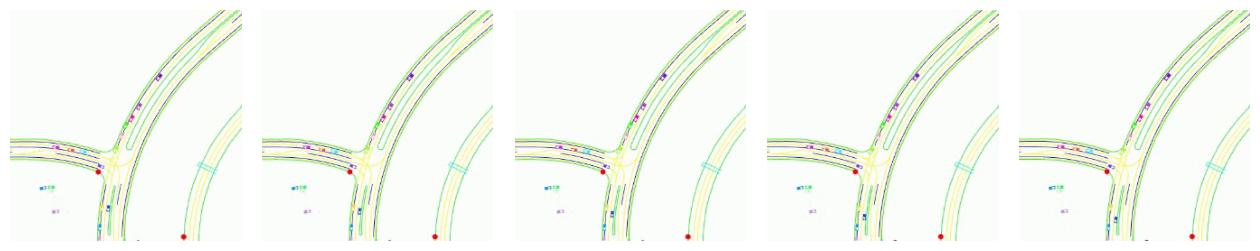

In [10]:
import numpy as np
from openstl.utils import show_video_line

# exp_name = 'tau_10ep_color'
#results.clear()

import gc
gc.collect()

# show the given frames from an example
inputs = np.load('./work_dirs/'+exp_name+'/saved/inputs.npy')
preds = np.load('./work_dirs/'+exp_name+'/saved/preds.npy')
trues = np.load('./work_dirs/'+exp_name+'/saved/trues.npy')

example_idx = 0
show_video_line(trues[example_idx], ncols=aft_seq_length, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

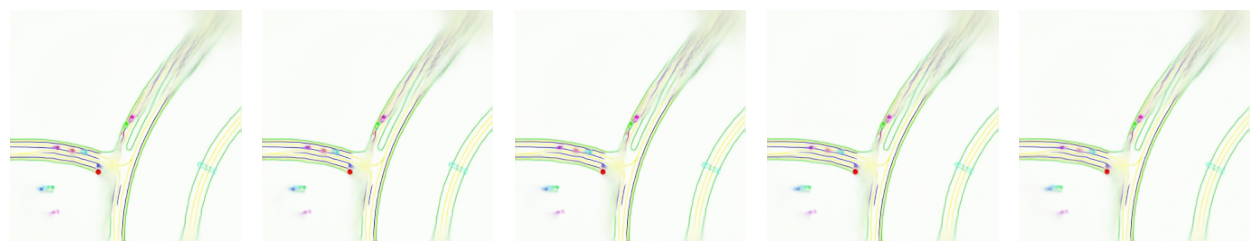

In [11]:
example_idx = 0
show_video_line(preds[example_idx], ncols=aft_seq_length, vmax=0.6, cbar=False, out_path=None, format='png', use_rgb=True)

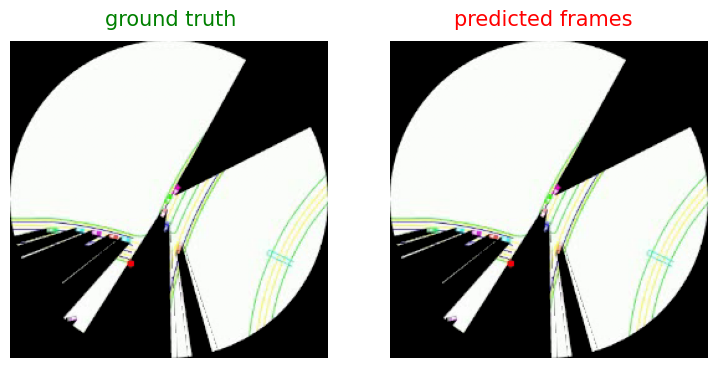

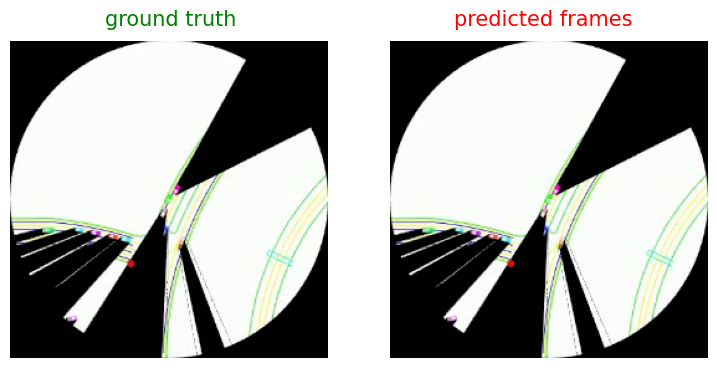

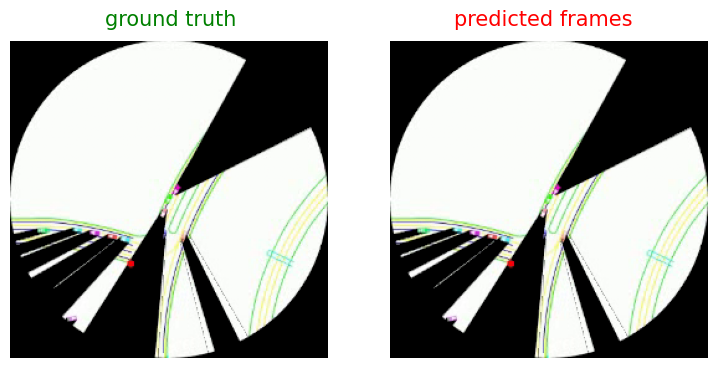

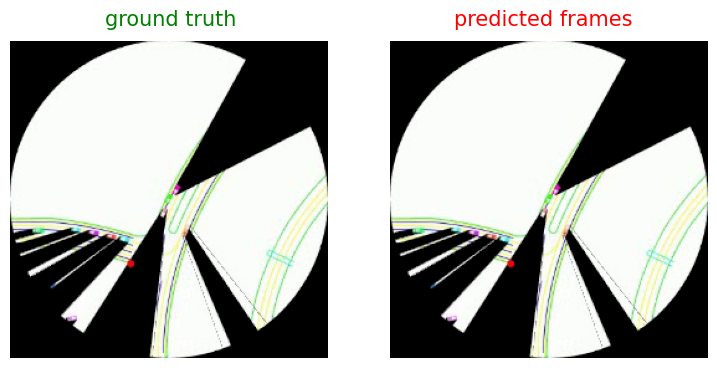

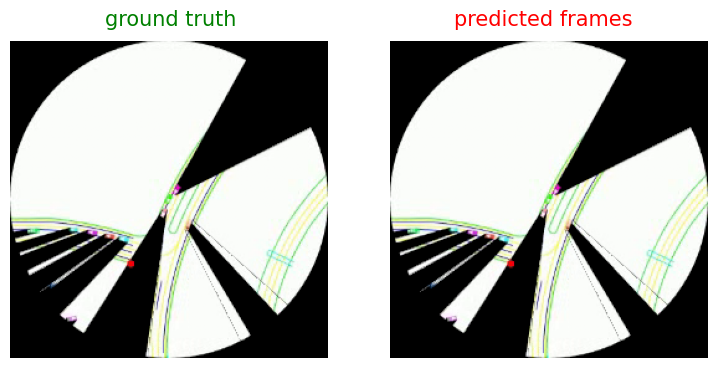

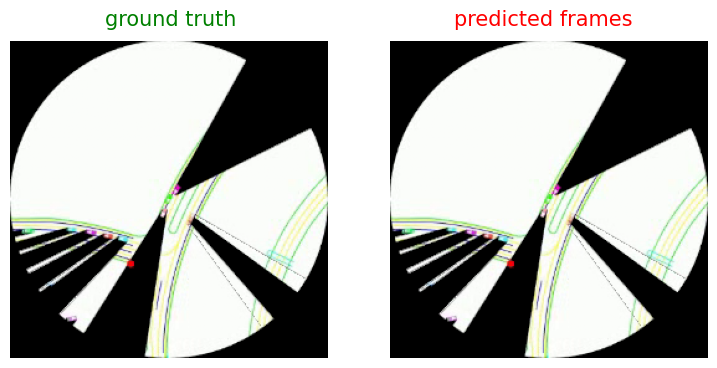

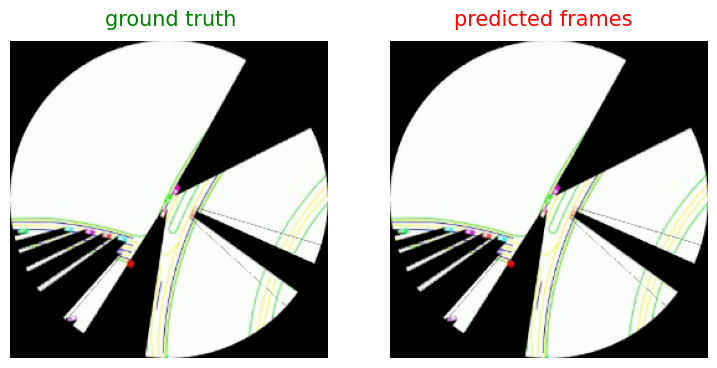

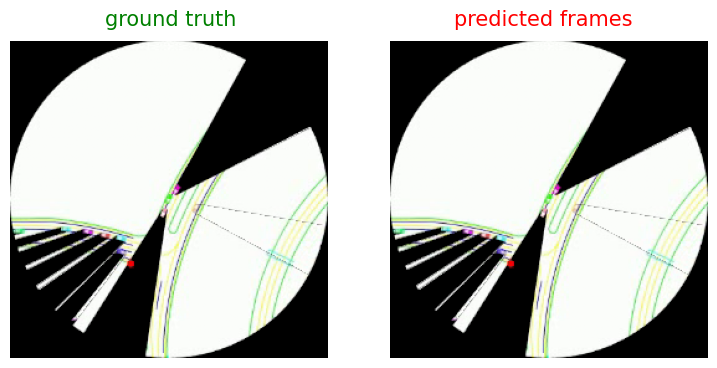

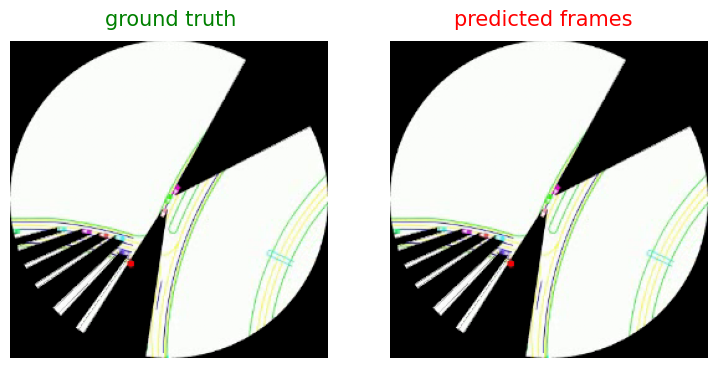

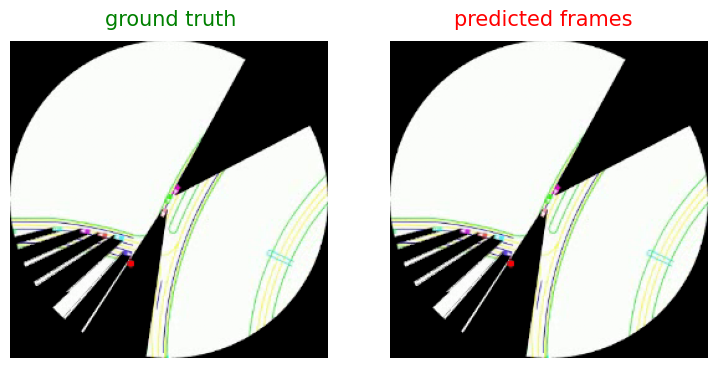

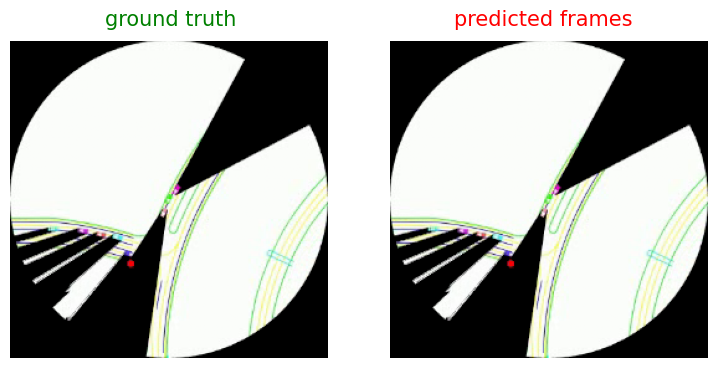

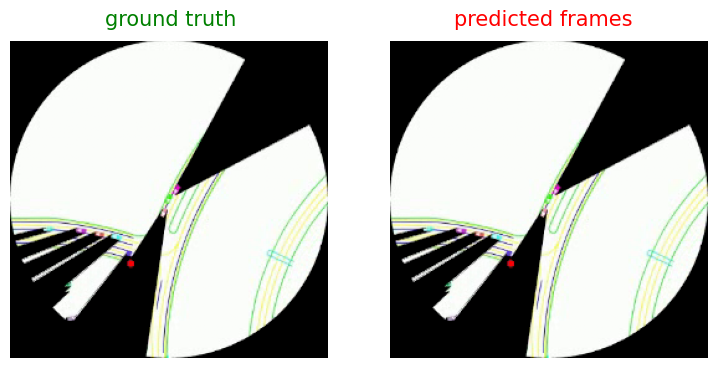

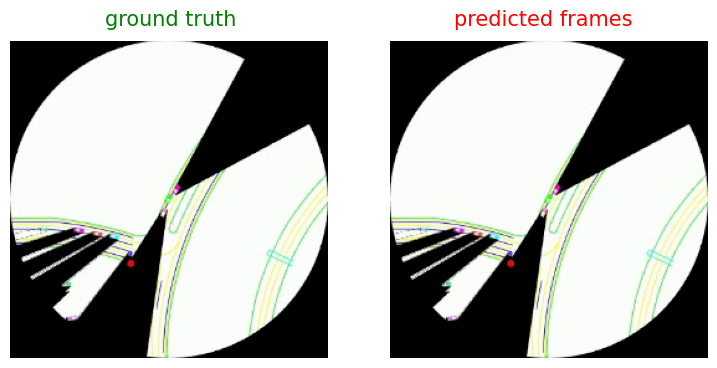

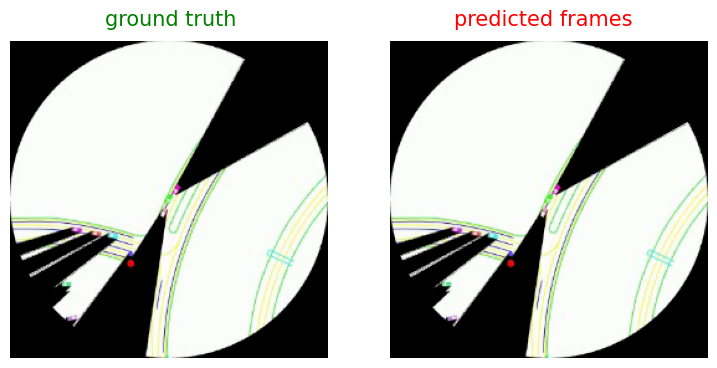

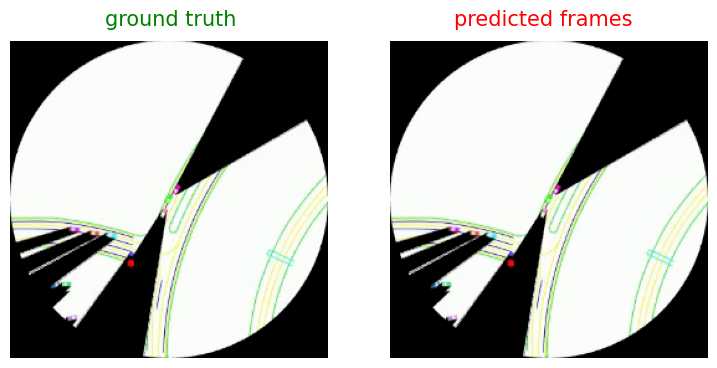

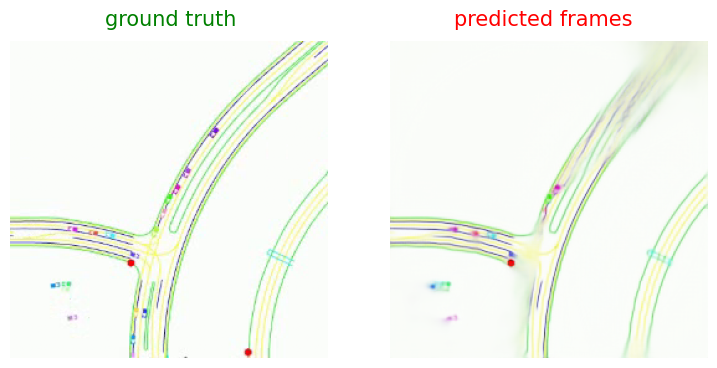

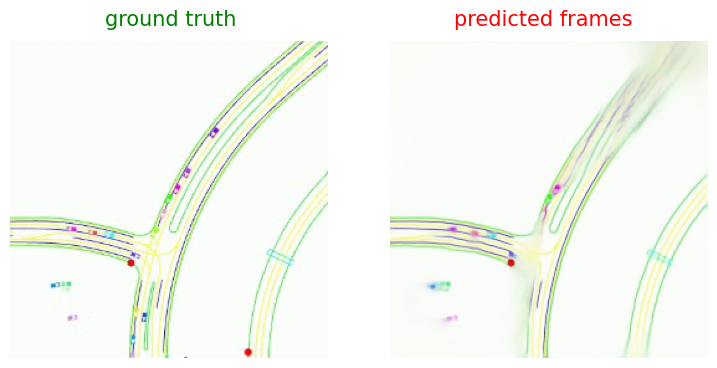

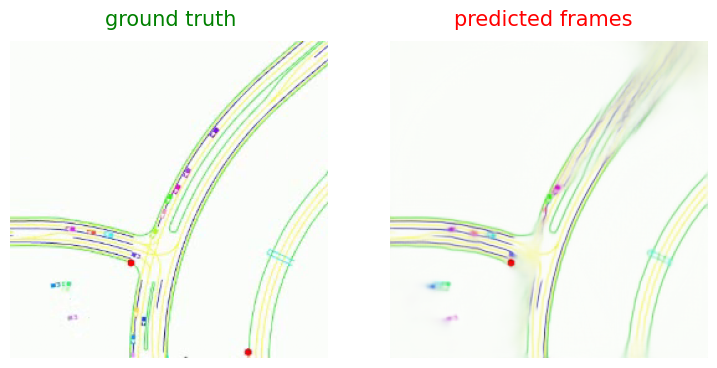

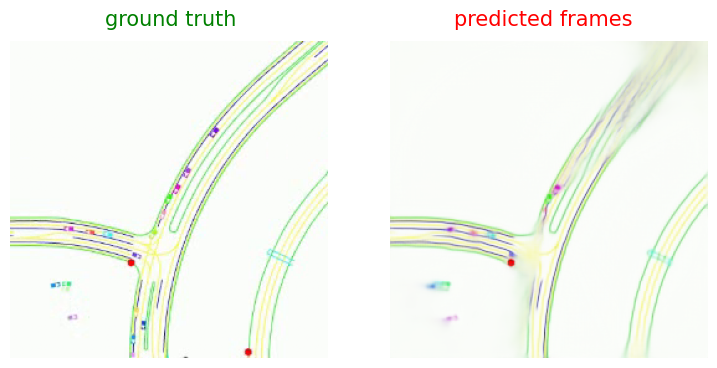

In [12]:
from openstl.utils import show_video_gif_multiple

example_idx = 0
show_video_gif_multiple(inputs[example_idx], trues[example_idx], preds[example_idx], use_rgb=True, out_path='example.gif')

In [13]:
# print(trues[example_idx])